# Header

## Smaller header
-
-
-


*italic*
**bold**

### Smallest one

In [11]:
import pandas as pd
from matplotlib import pyplot as plt

from ipywidgets import IntSlider, Play, jslink, VBox, interact
from ipywidgets import interactive_output


In [12]:
CSV_PATH = "25C/Acute/raw_csv/Acute-25C-CIP-R-090625.csv"


In [13]:
import os

def generate_smooth_plot_csv(csv_path: str, window: int, save_output: bool = False) -> None:
	df = pd.read_csv(csv_path, delimiter=';')
	df_smoothed = df.copy()
	df_smoothed['T. (ºC)'] = df['T. (ºC)'].rolling(window=window, min_periods=1).mean()
	df_smoothed['Rs (mg/l.h)'] = df['Rs (mg/l.h)'].rolling(window=window, min_periods=1).mean()

	fig, ax1 = plt.subplots(figsize=(10, 6))
	ax1.plot(df_smoothed['Time (Day:Hour:Minute:Second)'], df_smoothed['T. (ºC)'], color='tab:blue', label='T. (ºC) (smoothed)')
	ax1.set_xlabel('Time (Day:Hour:Minute:Second)')
	ax1.set_ylabel('T. (ºC)', color='tab:blue')
	ax1.tick_params(axis='y', labelcolor='tab:blue')
	ax1.set_ylim(20, 30)

	ax2 = ax1.twinx()
	ax2.plot(df_smoothed['Time (Day:Hour:Minute:Second)'], df_smoothed['Rs (mg/l.h)'], color='tab:red', label='Rs (mg/l.h) (smoothed)')
	ax2.set_ylabel('Rs (mg/l.h)', color='tab:red')
	ax2.tick_params(axis='y', labelcolor='tab:red')
	ax2.set_ylim(-5, 60)

	fig.tight_layout()
	plt.title(f'Smoothed T. (ºC) and Rs (mg/l.h) vs Time (Moving Average Window={window})')
	plt.show()

	file_name_base = os.path.splitext(os.path.basename(csv_path))[0]
	output_dir = os.path.join(os.getcwd(), "25C/Acute/processed")
	os.makedirs(output_dir, exist_ok=True)

	if save_output:
		df_smoothed.to_csv(os.path.join(output_dir, f"{file_name_base}_moving_average_{window}.csv"), index=False)
		df_smoothed.to_excel(os.path.join(output_dir, f"{file_name_base}_moving_average_{window}.xlsx"), index=False)

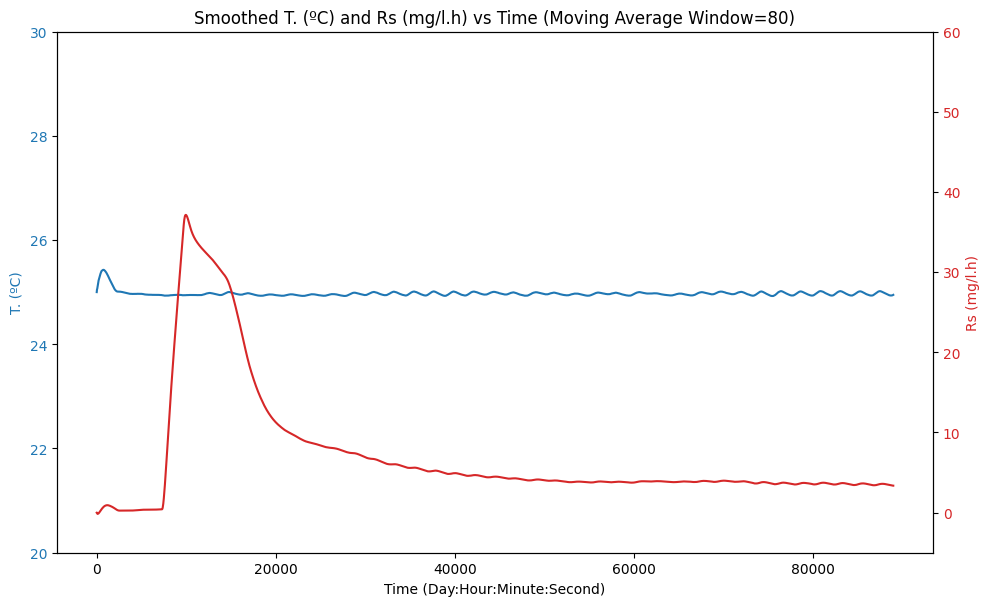

In [14]:
generate_smooth_plot_csv(CSV_PATH, window=80, save_output=True)

In [ ]:

interact(generate_smooth_plot_csv, csv_path=CSV_PATH, window=IntSlider(min=0, max=100, step=1, value=38, description='Window Size'));

interactive(children=(Text(value='25C/Acute/raw_csv/Acute-25C-CIP-R-090625.csv', description='csv_path'), IntS…